# Online Retail Sales Analysis

## Objective

Analyze transactional retail data to understand sales performance,
customer behavior, product performance, and revenue trends.

The analysis will focus on identifying key business patterns and
producing insights that can be communicated through a Power BI dashboard.

In [4]:
import pandas as pd

df = pd.read_excel('../data/Online_Retail.xlsx')

## Initial Data Exploration

Before cleaning or analyzing the dataset, I first inspected its structure,
columns, data types, missing values, and basic descriptive statistics.

In [5]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [6]:
# df.shape
# df.columns
# df.info()
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [7]:
# df.isna().sum()
df.nunique()

InvoiceNo      25900
StockCode       4070
Description     4223
Quantity         722
InvoiceDate    23260
UnitPrice       1630
CustomerID      4372
Country           38
dtype: int64

In [8]:
negative_quantity = df[df["Quantity"] < 0]
negative_price = df[df["UnitPrice"] < 0]

In [9]:
negative_quantity.head()
# negative_price.head()
# negative_quantity.shape
# negative_price.shape

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom


In [10]:
# negative_quantity["InvoiceNo"].head(20)
df[df["Quantity"] > 0]["InvoiceNo"].head(20)

0     536365
1     536365
2     536365
3     536365
4     536365
5     536365
6     536365
7     536366
8     536366
9     536367
10    536367
11    536367
12    536367
13    536367
14    536367
15    536367
16    536367
17    536367
18    536367
19    536367
Name: InvoiceNo, dtype: object

In [11]:
# df["StockCode"].dtype
# negative_quantity.loc[
#     negative_quantity["StockCode"].astype(str).str.contains("37448", na=False)
# ]
matches = df[
    (df["StockCode"].astype(str) == '37448') &
    (df["CustomerID"].astype(str) == '14796.0')
].sort_values("InvoiceDate")
print(matches[[
    "InvoiceNo",
    "StockCode",
    "Description",
    "Quantity",
    "InvoiceDate",
    "UnitPrice",
    "CustomerID"
]])

       InvoiceNo StockCode                      Description  Quantity  \
17238     537692     37448  CERAMIC CAKE DESIGN SPOTTED MUG         6   
27366     538533     37448  CERAMIC CAKE DESIGN SPOTTED MUG         7   
68421    C541868     37448  CERAMIC CAKE DESIGN SPOTTED MUG        -4   
68721     541872     37448  CERAMIC CAKE DESIGN SPOTTED MUG         6   
87344     543653     37448  CERAMIC CAKE DESIGN SPOTTED MUG         4   
96053     544476     37448  CERAMIC CAKE DESIGN SPOTTED MUG         6   
109181    545587     37448  CERAMIC CAKE DESIGN SPOTTED MUG         8   
133239    547730     37448  CERAMIC CAKE DESIGN SPOTTED MUG         8   
157208   C550195     37448  CERAMIC CAKE DESIGN SPOTTED MUG        -1   
157230    550196     37448  CERAMIC CAKE DESIGN SPOTTED MUG         7   
177235    552051     37448  CERAMIC CAKE DESIGN SPOTTED MUG         6   
233718    557484     37448  CERAMIC CAKE DESIGN SPOTTED MUG         8   
258761    559672     37448  CERAMIC CAKE DESIGN SPO

In [12]:
first = negative_quantity.shape[0]
print(first, negative_quantity["InvoiceNo"].astype(str).str.startswith('C').sum())

10624 9288


In [13]:
negative_non_cancelled = negative_quantity[~negative_quantity["InvoiceNo"].astype(str).str.startswith("C")]
negative_non_cancelled.head(20)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom
4347,536764,84952C,NaN,-38,2010-12-02 14:42:00,0.0,NaN,United Kingdom
7188,536996,22712,NaN,-20,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7189,536997,22028,NaN,-20,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7190,536998,85067,NaN,-6,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7192,537000,21414,NaN,-22,2010-12-03 15:32:00,0.0,NaN,United Kingdom
7193,537001,21653,NaN,-6,2010-12-03 15:33:00,0.0,NaN,United Kingdom
7195,537003,85126,NaN,-2,2010-12-03 15:33:00,0.0,NaN,United Kingdom
7196,537004,21814,NaN,-30,2010-12-03 15:34:00,0.0,NaN,United Kingdom
7197,537005,21692,NaN,-70,2010-12-03 15:35:00,0.0,NaN,United Kingdom


In [14]:
negative_non_cancelled["Description"].value_counts().head(20)

Description
check                     120
damages                    45
damaged                    42
?                          41
sold as set on dotcom      20
Damaged                    14
thrown away                 9
Unsaleable, destroyed.      9
??                          7
wet damaged                 5
damages?                    5
ebay                        5
smashed                     4
missing                     3
wet pallet                  3
CHECK                       3
sold as 1                   2
incorrect stock entry.      2
crushed                     2
adjustment                  2
Name: count, dtype: int64

In [15]:
zero_values = df[df["UnitPrice"] == 0]

In [16]:
zero_values["Description"].value_counts()

Description
check                                  159
?                                       47
damages                                 45
damaged                                 43
found                                   25
                                      ... 
HEART GARLAND RUSTIC PADDED              1
CHICK GREY HOT WATER BOTTLE              1
mystery! Only ever imported 1800         1
MERCHANT CHANDLER CREDIT ERROR, STO      1
lost                                     1
Name: count, Length: 376, dtype: int64

## Data Quality Findings

Initial exploration identified several data quality considerations:

- The dataset contains 541,909 invoice line items across 8 columns.
- `Description` contains missing values, while `CustomerID` has a substantial number of missing records.
- Negative quantities occur frequently. Most are associated with invoice numbers beginning with `C`, indicating cancelled or returned transactions.
- Other negative-quantity records appear to represent inventory or administrative adjustments, with descriptions such as "damages" and "check".
- A small number of negative unit prices are associated with accounting adjustments such as "Adjust bad debt".
- Zero-price records frequently appear to represent inventory or administrative activity rather than normal customer sales.

These findings will be considered when preparing the data for sales and customer analysis.

In [17]:
df["Revenue"] = df["UnitPrice"] * df["Quantity"]
df[["Quantity", "UnitPrice", "Revenue"]].head()

,Quantity,UnitPrice,Revenue
0,6,2.55,15.30
1,6,3.39,20.34
2,8,2.75,22.00
3,6,3.39,20.34
4,6,3.39,20.34


In [18]:
df["Revenue"].describe()

count    541909.000000
mean         17.987795
std         378.810824
min     -168469.600000
25%           3.400000
50%           9.750000
75%          17.400000
max      168469.600000
Name: Revenue, dtype: float64

## Business Analysis

Questions about the business in relation to the data

### How is the business performing overall?
- Gross Revenue
- Net Revenue
- Number of Orders
- Number of Customers
- Average Order Value

In [19]:
customer_transactions = df[df["CustomerID"].notna()]

In [20]:
customer_transactions.shape

(406829, 9)

For `customer_transactions` we dropped rows without a customer id, but we still can have non valid sales transactions which requires more cleaning. 

In [21]:
positive_customer_quantity = customer_transactions[customer_transactions["Quantity"] > 0]
negative_customer_quantity = customer_transactions[customer_transactions["Quantity"] < 0]

In [22]:
negative_shape = negative_customer_quantity["InvoiceNo"].astype(str).str.startswith('C').sum()
print(negative_customer_quantity.shape[0], negative_shape)

8905 8905


In [23]:
gross_revenue = positive_customer_quantity["Revenue"].sum()
print(gross_revenue)

8911407.904


In [24]:
cancellation_revenue = negative_customer_quantity["Revenue"].sum()
print(cancellation_revenue)

-611342.0900000001


In [25]:
net_revenue = gross_revenue + cancellation_revenue
print(net_revenue)

8300065.813999999


In [26]:
completed_orders = positive_customer_quantity["InvoiceNo"].nunique()
print(completed_orders)

18536


In [27]:
print(f'Gross Revenue: £{gross_revenue:,.2f}')
print(f'Cancellation Revenue: £{cancellation_revenue:,.2f}')
print(f'Net Revenue: £{net_revenue:,.2f}')
print(f'Completed Orders: {completed_orders:,}')

Gross Revenue: £8,911,407.90
Cancellation Revenue: £-611,342.09
Net Revenue: £8,300,065.81
Completed Orders: 18,536


In [28]:
order_totals = positive_customer_quantity.groupby('InvoiceNo')['Revenue'].sum()
print(order_totals)

InvoiceNo
536365    139.12
536366     22.20
536367    278.73
536368     70.05
536369     17.85
           ...  
581583    124.60
581584    140.64
581585    329.05
581586    339.20
581587    249.45
Name: Revenue, Length: 18536, dtype: float64


In [29]:
average_orders_total = order_totals.mean()
print(f'£{average_orders_total:.2f}')

£480.76


## Overall Sales Performance

For transactions associated with known customers:

- **Gross Revenue:** £8,911,407.90
- **Cancellation/Return Revenue:** -£611,342.09
- **Net Revenue:** £8,300,065.81
- **Completed Orders:** 18,536
- **Average Order Value:** £480.76

Cancellations and returns reduced gross customer revenue by approximately 6.9%.

In [30]:
positive_customer_quantity["year"] = positive_customer_quantity["InvoiceDate"].dt.year
positive_customer_quantity["month"] = positive_customer_quantity["InvoiceDate"].dt.month

monthly_revenue = positive_customer_quantity.groupby(["year", "month"])["Revenue"].sum()
monthly_revenue.head()

/var/folders/m5/gg0m54tn1tl9j8h7_dcbw0v40000gn/T/ipykernel_6897/2226419540.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  positive_customer_quantity["year"] = positive_customer_quantity["InvoiceDate"].dt.year
/var/folders/m5/gg0m54tn1tl9j8h7_dcbw0v40000gn/T/ipykernel_6897/2226419540.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  positive_customer_quantity["month"] = positive_customer_quantity["InvoiceDate"].dt.month


year  month
2010  12       572713.890
2011  1        569445.040
      2        447137.350
      3        595500.760
      4        469200.361
Name: Revenue, dtype: float64

In [31]:
print(monthly_revenue)

year  month
2010  12        572713.890
2011  1         569445.040
      2         447137.350
      3         595500.760
      4         469200.361
      5         678594.560
      6         661213.690
      7         600091.011
      8         645343.900
      9         952838.382
      10       1039318.790
      11       1161817.380
      12        518192.790
Name: Revenue, dtype: float64


In [32]:
monthly_revenue = monthly_revenue.reset_index()

In [33]:
monthly_revenue["day"] = 1
monthly_revenue["date"] = pd.to_datetime(
    monthly_revenue[["year", "month", "day"]]
)
monthly_revenue.head()

,year,month,Revenue,day,date
0,2010,12,572713.890,1,2010-12-01
1,2011,1,569445.040,1,2011-01-01
2,2011,2,447137.350,1,2011-02-01
3,2011,3,595500.760,1,2011-03-01
4,2011,4,469200.361,1,2011-04-01


In [34]:
import matplotlib.pyplot as plt

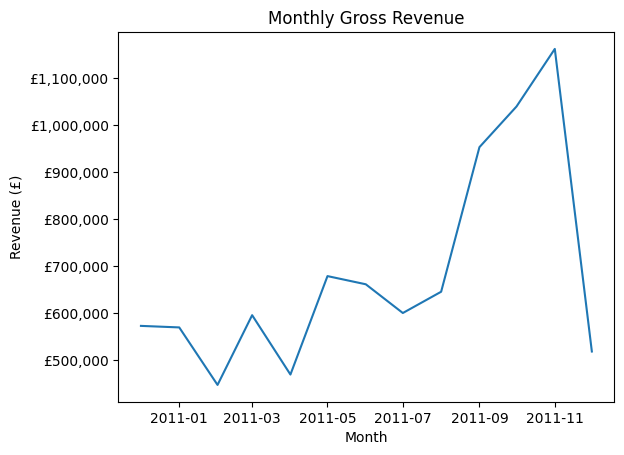

In [35]:
from matplotlib.ticker import FuncFormatter

plt.plot(monthly_revenue["date"], monthly_revenue["Revenue"])
plt.title("Monthly Gross Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")

def currency_formatter(x, pos):
    return f"£{x:,.0f}"

plt.gca().yaxis.set_major_formatter(FuncFormatter(currency_formatter))

plt.show()

In [36]:
print(positive_customer_quantity["InvoiceDate"].min())
print(positive_customer_quantity["InvoiceDate"].max())

2010-12-01 08:26:00
2011-12-09 12:50:00


**Observation:** Gross revenue remained relatively stable through much of early and
mid-2011 before increasing sharply from September through November. November
recorded the highest monthly gross revenue in the dataset.

The apparent decline in December 2011 should not be interpreted as a full
month-over-month decline because the dataset only contains transactions through
December 9, 2011.

In [37]:
product_performance = (
    positive_customer_quantity
    .groupby("StockCode")
    .agg(
        Units_Sold = ("Quantity", "sum"),
        Revenue = ("Revenue", "sum")
    )
    .reset_index()
)

product_performance.head()

,StockCode,Units_Sold,Revenue
0,10002,823,699.55
1,10080,291,114.41
2,10120,193,40.53
3,10125,1226,930.30
4,10133,2384,1143.61


In [38]:
specific_positive_quantity = positive_customer_quantity[positive_customer_quantity["StockCode"].isin(["POST", "M", 23843])]

In [39]:
specific_positive_quantity["StockCode"].value_counts()

StockCode
POST     1099
M         290
23843       1
Name: count, dtype: int64

In [40]:
specific_positive_quantity.groupby("StockCode")["Description"].value_counts()

StockCode  Description                
23843      PAPER CRAFT , LITTLE BIRDIE       1
M          Manual                          290
POST       POSTAGE                        1099
Name: count, dtype: int64

In [41]:
specific_positive_quantity[
    specific_positive_quantity["StockCode"] == 23843
]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,year,month
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446.0,United Kingdom,168469.6,2011,12


In [42]:
customer_transactions[
    customer_transactions["StockCode"] == 23843
]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446.0,United Kingdom,168469.6
540422,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,2.08,16446.0,United Kingdom,-168469.6


In [43]:
product_performance = customer_transactions.groupby("StockCode").agg(
    NetUnitsSold=("Quantity", "sum"),
    NetRevenue=("Revenue", "sum")
).reset_index()

In [44]:
product_performance = product_performance.sort_values(by="NetRevenue", ascending=False)
product_performance.head(10)

,StockCode,NetUnitsSold,NetRevenue
1222,22423,11555,132870.40
3366,85123A,34204,93979.20
3360,85099B,45066,83236.76
2412,47566,15027,67687.53
3683,POST,3002,66710.24
2610,84879,35314,56499.22
1853,23084,27094,51137.80
1296,22502,1413,46980.95
2476,79321,9570,45936.81
919,22086,15164,41500.48


In [45]:
customer_transactions[customer_transactions["StockCode"] == 22423].value_counts("Description")

Description
REGENCY CAKESTAND 3 TIER    1905
Name: count, dtype: int64

In [46]:
product_transactions = customer_transactions[~customer_transactions["StockCode"].isin(["POST", "M"])]
product_transactions.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [47]:
product_performance = product_transactions.groupby("StockCode").agg(
    NetUnitsSold=("Quantity", "sum"),
    NetRevenue=("Revenue", "sum")
).reset_index()

In [48]:
product_performance = product_performance.sort_values(by="NetRevenue", ascending=False)
product_performance.head(10)

,StockCode,NetUnitsSold,NetRevenue
1222,22423,11555,132870.40
3366,85123A,34204,93979.20
3360,85099B,45066,83236.76
2412,47566,15027,67687.53
2610,84879,35314,56499.22
1853,23084,27094,51137.80
1296,22502,1413,46980.95
2476,79321,9570,45936.81
919,22086,15164,41500.48
307,21137,11391,39009.38


In [49]:
product_transactions[
    product_transactions["StockCode"] == 22423
]["Description"].mode()

0    REGENCY CAKESTAND 3 TIER
Name: Description, dtype: object

In [50]:
product_descriptions = (
    product_transactions
    .groupby("StockCode")["Description"]
    .agg(lambda x: x.mode().iloc[0])
    .reset_index()
)

In [51]:
merged_product_performance = pd.merge(product_performance, product_descriptions, on="StockCode")
merged_product_performance = merged_product_performance.sort_values(by="NetRevenue", ascending=False).reset_index(drop=True)
merged_product_performance.head(10)

,StockCode,NetUnitsSold,NetRevenue,Description
0,22423,11555,132870.40,REGENCY CAKESTAND 3 TIER
1,85123A,34204,93979.20,WHITE HANGING HEART T-LIGHT HOLDER
2,85099B,45066,83236.76,JUMBO BAG RED RETROSPOT
3,47566,15027,67687.53,PARTY BUNTING
4,84879,35314,56499.22,ASSORTED COLOUR BIRD ORNAMENT
5,23084,27094,51137.80,RABBIT NIGHT LIGHT
6,22502,1413,46980.95,PICNIC BASKET WICKER SMALL
7,79321,9570,45936.81,CHILLI LIGHTS
8,22086,15164,41500.48,PAPER CHAIN KIT 50'S CHRISTMAS
9,21137,11391,39009.38,BLACK RECORD COVER FRAME


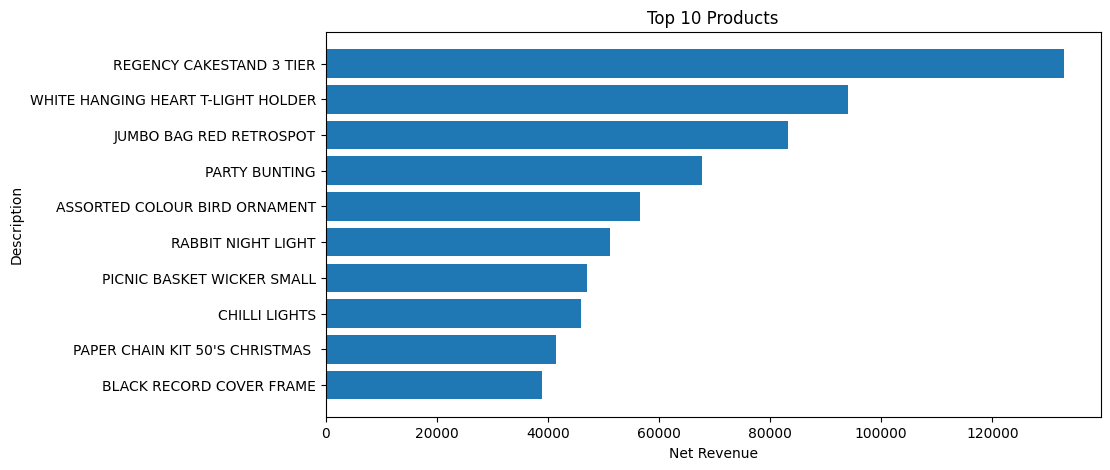

In [53]:
top_10_products = merged_product_performance.head(10)

plt.figure(figsize=(10, 5))
plt.barh(
    top_10_products["Description"],
    top_10_products["NetRevenue"]
)

plt.title('Top 10 Products')
plt.xlabel('Net Revenue')
plt.ylabel('Description')

plt.gca().invert_yaxis()

plt.show()

In [57]:
country_performance = customer_transactions.groupby('Country')['Revenue'].sum().reset_index().rename(columns={'Revenue': 'NetRevenue'})
country_performance = country_performance.sort_values(by='NetRevenue', ascending=False)

In [72]:
country_performance.head(10)

,Country,NetRevenue
35,United Kingdom,6767873.394
23,Netherlands,284661.540
10,EIRE,250285.220
14,Germany,221698.210
13,France,196712.840
0,Australia,137077.270
32,Switzerland,55739.400
30,Spain,54774.580
3,Belgium,40910.960
31,Sweden,36595.910


In [73]:
UK_NetRev = country_performance.loc[country_performance['Country'] == 'United Kingdom', 'NetRevenue'].item()
total_NetRev = country_performance["NetRevenue"].sum()
UK_Revenue_Share = round((UK_NetRev/total_NetRev) * 100, 2)
print(UK_Revenue_Share)

81.54


In [75]:
international_performance = country_performance[country_performance["Country"] != 'United Kingdom'].head(10).reset_index(drop=True)
international_performance.head()

,Country,NetRevenue
0,Netherlands,284661.54
1,EIRE,250285.22
2,Germany,221698.21
3,France,196712.84
4,Australia,137077.27


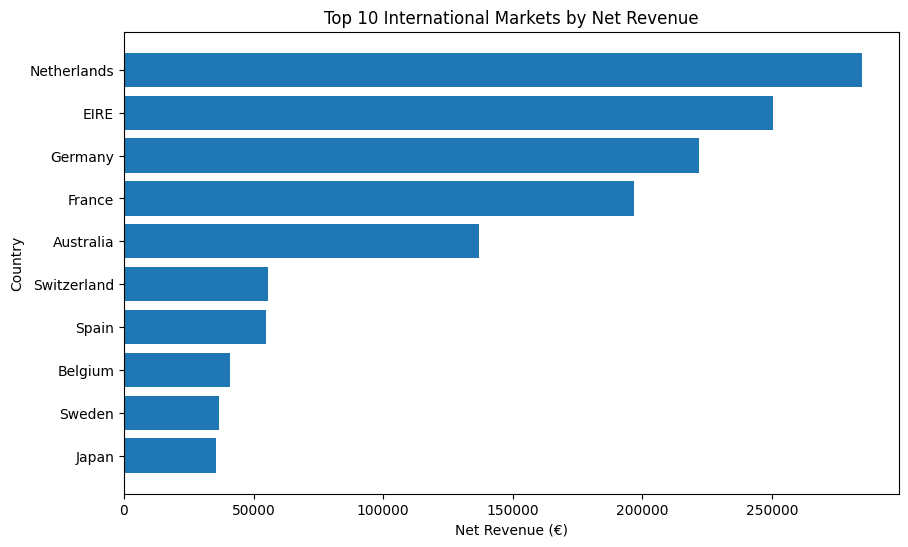

In [79]:
plt.figure(figsize=(10, 6))
plt.barh(international_performance["Country"], international_performance["NetRevenue"])

plt.xlabel('Net Revenue (€)')
plt.ylabel('Country')
plt.title('Top 10 International Markets by Net Revenue')

plt.gca().invert_yaxis()
plt.show()

In [81]:
customer_summary = (
    positive_customer_quantity.groupby('CustomerID')
    .agg(
        TotalRevenue = ('Revenue', 'sum'),
        OrderCount = ('InvoiceNo', 'nunique')
    )
).reset_index()

In [82]:
customer_summary.head()

,CustomerID,TotalRevenue,OrderCount
0,12346.0,77183.60,1
1,12347.0,4310.00,7
2,12348.0,1797.24,4
3,12349.0,1757.55,1
4,12350.0,334.40,1


In [85]:
repeat_customers = customer_summary[customer_summary["OrderCount"] > 1]
rep_cust_num = repeat_customers.shape[0]

In [87]:
total_customers = customer_summary.shape[0]
repeat_customer_rate = round((rep_cust_num/total_customers) * 100, 2)
print(f'{repeat_customer_rate}%')

65.57%


In [90]:
total_rev_rep_cust = repeat_customers["TotalRevenue"].sum()
total_rev_cust_sum = customer_summary["TotalRevenue"].sum()
total_rev_rep_cust_rate = round((total_rev_rep_cust/total_rev_cust_sum)*100,2)
print(f'{total_rev_rep_cust_rate}%')

93.08%


## Customer Behavior Analysis

Approximately 65.57% of customers placed more than one order during
the observed period.

These repeat customers generated 93.08% of total revenue from
identified customers, highlighting the importance of repeat purchasing
to the retailer's sales performance.

In [92]:
customer_summary["AvgOrderValue"] = round(customer_summary["TotalRevenue"]/customer_summary["OrderCount"],2)
customer_summary.head()

,CustomerID,TotalRevenue,OrderCount,AvgOrderValue
0,12346.0,77183.60,1,77183.60
1,12347.0,4310.00,7,615.71
2,12348.0,1797.24,4,449.31
3,12349.0,1757.55,1,1757.55
4,12350.0,334.40,1,334.40


In [94]:
import numpy as np

In [96]:
customer_summary["CustomerType"] = np.where(customer_summary["OrderCount"] > 1, "Repeat", "One-Time")

In [101]:
customer_type_summary = customer_summary.groupby("CustomerType").agg(
    TotalRevenue = ("TotalRevenue", "sum"),
    TotalOrders = ("OrderCount", "sum")
).reset_index()

customer_type_summary["TotalRevenue"] = round(customer_type_summary["TotalRevenue"],2)

customer_type_summary["AvgOrderValue"] = round(customer_type_summary["TotalRevenue"]/customer_type_summary["TotalOrders"],2)
customer_type_summary.head()

,CustomerType,TotalRevenue,TotalOrders,AvgOrderValue
0,One-Time,616311.73,1494,412.52
1,Repeat,8295096.17,17042,486.74


### Repeat vs. One-Time Customers

Repeat customers generated approximately 93.08% of revenue from identified customers.

Their average order value was £486.74, compared with £412.52 for one-time customers, representing an approximately 18% difference.

This suggests that repeat customers contribute to revenue not only through more frequent purchasing but also through higher average order values.

In [105]:
top_10_customers = customer_summary.sort_values(by="TotalRevenue", ascending=False)[0:10].reset_index(drop=True)

In [106]:
top_10_revenue_share = round((top_10_customers["TotalRevenue"].sum()/total_rev_cust_sum)*100,2)
print(f'{top_10_revenue_share}%')

17.26%


### Customer Revenue Concentration

The 10 highest-spending customers account for 17.26% of total
revenue from identified customers.

This indicates that a relatively small group of customers contributes
a meaningful portion of revenue. Retaining high-value customers may
therefore be important to the retailer's overall sales performance.

In [108]:
print(customer_transactions.shape)
print(customer_transactions.dtypes)

(406829, 9)
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
Revenue               float64
dtype: object


In [109]:
customer_transactions = customer_transactions.copy()

customer_transactions["CustomerID"] = (
    customer_transactions["CustomerID"].astype(int)
)

In [110]:
customer_transactions.to_csv(
    "../data/customer_transactions.csv",
    index=False
)

## SQL Analysis

The cleaned transaction-level dataset is loaded into SQLite to perform
additional business analysis using SQL queries.

In [111]:
import sqlite3

conn = sqlite3.connect("../data/retail.db")

In [112]:
customer_transactions.to_sql(
    "transactions",
    conn,
    if_exists="replace",
    index=False
)

406829

In [113]:
pd.read_sql_query(
    """
    SELECT *
    FROM transactions
    LIMIT 5;
    """,
    conn
)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


In [114]:
pd.read_sql_query(
    """
    SELECT COUNT(*)
    FROM transactions;
    """,
    conn
)

,COUNT(*)
0,406829


In [117]:
pd.read_sql_query(
    """
    SELECT
        SUM(CASE WHEN Quantity > 0 THEN Revenue ELSE 0 END) as gross_revenue,
        SUM(CASE WHEN Quantity < 0 THEN Revenue ELSE 0 END) as cancellation_revenue,
        SUM(Revenue) as net_revenue
    FROM transactions
    """,
    conn
)

,gross_revenue,cancellation_revenue,net_revenue
0,8911407.904,-611342.09,8300065.814


In [123]:
pd.read_sql_query(
    """
    with month_by_month as (
        SELECT
        strftime('%Y-%m', InvoiceDate) AS Month,
        *
        FROM transactions
    )

    SELECT Month, Sum(Revenue) as NetRevenue FROM month_by_month
    group by Month
    order by Month asc;
    """,
    conn
)

,Month,NetRevenue
0,2010-12,554604.020
1,2011-01,475074.380
2,2011-02,436546.150
3,2011-03,579964.610
4,2011-04,426047.851
5,2011-05,648251.080
6,2011-06,608013.160
7,2011-07,574238.481
8,2011-08,616368.000
9,2011-09,931440.372


In [133]:
pd.read_sql_query(
    """
    WITH monthly_revenue AS (
        SELECT
            strftime('%Y-%m', InvoiceDate) AS Month,
            SUM(Revenue) AS NetRevenue
        FROM transactions
        GROUP BY strftime('%Y-%m', InvoiceDate)
    ),
    revenue_with_previous AS (
        SELECT
            Month,
            NetRevenue,
            LAG(NetRevenue) OVER (ORDER BY Month) AS PreviousRevenue
        FROM monthly_revenue
    )

    SELECT 
        Month, 
        NetRevenue,
        PreviousRevenue,
        Round(((NetRevenue - PreviousRevenue)/PreviousRevenue) * 100,2) as GrowthPct
    FROM revenue_with_previous
    Order By Month asc;
    """,
    conn
)

,Month,NetRevenue,PreviousRevenue,GrowthPct
0,2010-12,554604.020,NaN,NaN
1,2011-01,475074.380,554604.020,-14.34
2,2011-02,436546.150,475074.380,-8.11
3,2011-03,579964.610,436546.150,32.85
4,2011-04,426047.851,579964.610,-26.54
5,2011-05,648251.080,426047.851,52.15
6,2011-06,608013.160,648251.080,-6.21
7,2011-07,574238.481,608013.160,-5.55
8,2011-08,616368.000,574238.481,7.34
9,2011-09,931440.372,616368.000,51.12


In [134]:
pd.read_sql_query(
    """
    select CustomerID, Sum(Revenue) as TotalRevenue, Count(distinct InvoiceNo) as OrderCount from transactions
    where Quantity > 0
    group by CustomerID
    order by TotalRevenue desc
    Limit 10;
    """,
    conn
)

,CustomerID,TotalRevenue,OrderCount
0,14646,280206.02,74
1,18102,259657.30,60
2,17450,194550.79,46
3,16446,168472.50,2
4,14911,143825.06,201
5,12415,124914.53,21
6,14156,117379.63,55
7,17511,91062.38,31
8,16029,81024.84,63
9,12346,77183.60,1


In [135]:
conn.execute("""
    CREATE VIEW IF NOT EXISTS customers AS
    SELECT
        CustomerID,
        MIN(Country) AS Country
    FROM transactions
    GROUP BY CustomerID;
""")

In [136]:
conn.execute("""
    CREATE VIEW IF NOT EXISTS customer_orders AS
    SELECT
        CustomerID,
        SUM(Revenue) AS TotalRevenue,
        COUNT(DISTINCT InvoiceNo) AS OrderCount
    FROM transactions
    WHERE Quantity > 0
    GROUP BY CustomerID;
""")

In [138]:
pd.read_sql_query(
    """
    select customers.CustomerID, Country, TotalRevenue, OrderCount from customers
    left join customer_orders
        on customers.CustomerID = customer_orders.CustomerID
    order by TotalRevenue desc
    LIMIT 10
    """,
    conn
)

,CustomerID,Country,TotalRevenue,OrderCount
0,14646,Netherlands,280206.02,74
1,18102,United Kingdom,259657.30,60
2,17450,United Kingdom,194550.79,46
3,16446,United Kingdom,168472.50,2
4,14911,EIRE,143825.06,201
5,12415,Australia,124914.53,21
6,14156,EIRE,117379.63,55
7,17511,United Kingdom,91062.38,31
8,16029,United Kingdom,81024.84,63
9,12346,United Kingdom,77183.60,1
